In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
data=pd.read_csv('D:\gen AI\Deep Learning\code\AI_ML_Internship_Task\Data\customer_churn.csv')

In [3]:
data.head()

,age,gender,city,state,tenure_months,contract_type,payment_method,monthly_charges,total_charges,internet_service,support_calls,complaints,late_payments,satisfaction_score,is_active,churn
0,34,Female,Thane,Maharashtra,49,One year,Debit Card,922.560000,44669.56,DSL,4,0,2,6.4,1,0
1,36,Male,Delhi,Delhi,36,One year,Cash,830.350000,27906.89,Fiber optic,1,1,2,6.3,1,0
2,44,Female,Thane,Maharashtra,19,Month-to-month,Net Banking,857.009705,21773.37,Fiber optic,2,0,0,7.0,1,0
3,32,Female,Thane,Maharashtra,10,Two year,Net Banking,491.450000,4395.73,Fiber optic,5,1,1,5.8,0,1
4,38,Male,Bengaluru,Karnataka,32,One year,Debit Card,918.480000,26592.17,Fiber optic,1,0,3,7.9,1,0


In [4]:
data.columns

Index(['age', 'gender', 'city', 'state', 'tenure_months', 'contract_type',
       'payment_method', 'monthly_charges', 'total_charges',
       'internet_service', 'support_calls', 'complaints', 'late_payments',
       'satisfaction_score', 'is_active', 'churn'],
      dtype='object')

In [5]:
data.describe()

,age,tenure_months,monthly_charges,total_charges,support_calls,complaints,late_payments,satisfaction_score,is_active,churn
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,39.614867,25.000600,856.624961,21401.254863,2.124933,0.784400,1.112933,6.796721,0.816400,0.168067
std,12.473224,14.538855,345.495565,15474.203092,1.644923,0.892171,1.053686,1.628982,0.387171,0.373938
min,18.000000,1.000000,199.000000,380.550000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,14.000000,637.985000,10156.917500,1.000000,0.000000,0.000000,5.700000,1.000000,0.000000
50%,39.000000,22.000000,856.325000,17850.900000,2.000000,1.000000,1.000000,6.800000,1.000000,0.000000
75%,48.000000,33.000000,1061.932500,28316.022500,3.000000,1.000000,2.000000,7.900000,1.000000,0.000000
max,80.000000,72.000000,8305.870000,157423.150000,38.000000,6.000000,7.000000,12.000000,1.000000,1.000000


In [6]:
data.describe(include='object')

,gender,city,state,contract_type,payment_method,internet_service
count,15000,15000,15000,15000,15000,15000
unique,3,11,7,3,6,4
top,Female,Mumbai,Maharashtra,Month-to-month,Cash,Fiber optic
freq,7585,2385,7074,7800,3294,7178


In [7]:
data['churn'].value_counts(normalize=True)*100

churn
0    83.193333
1    16.806667
Name: proportion, dtype: float64

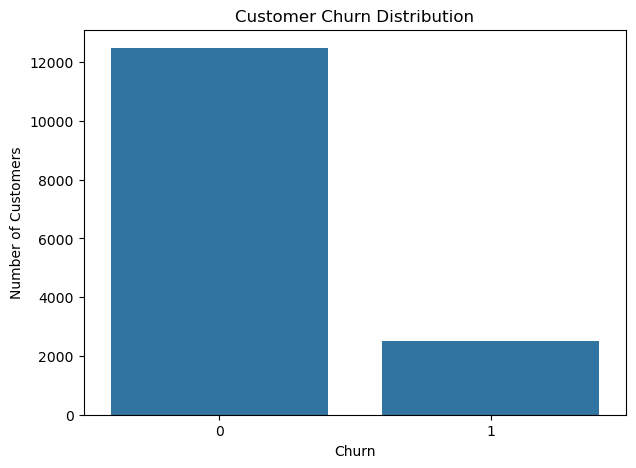

In [8]:
plt.figure(figsize=(7,5))
sns.countplot(data=data,x='churn')
plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.show()

'''
# Observation
The target variable contains two classes:
-0-> Customer did not churn
-1-> Customer churned

The dataset is imbalanced becouse the number of non-churn
customers is much higher then the number of churn customers.

Therefore, accuracy alone should not be used to judge the model. 
precision, Recall, F1-Score and Confussion Matrix will also be considered.
'''

In [9]:
X=data.drop(['churn'],axis=1)
y=data['churn']


In [10]:
print('Features shape:',X.shape)
print('Target shape:',y.shape)

Features shape: (15000, 15)
Target shape: (15000,)


In [11]:
print('Input Feature:')
for col in X.columns:
    print('',col)
print("\nTarget:",'churn')

Input Feature:
 age
 gender
 city
 state
 tenure_months
 contract_type
 payment_method
 monthly_charges
 total_charges
 internet_service
 support_calls
 complaints
 late_payments
 satisfaction_score
 is_active

Target: churn


In [12]:
numerical=X.select_dtypes(include=['int64','float64']).columns.tolist()
categorical=X.select_dtypes(include=['object']).columns.tolist()

In [13]:
numerical

['age',
 'tenure_months',
 'monthly_charges',
 'total_charges',
 'support_calls',
 'complaints',
 'late_payments',
 'satisfaction_score',
 'is_active']

In [14]:
categorical

['gender',
 'city',
 'state',
 'contract_type',
 'payment_method',
 'internet_service']

In [15]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("training data:",X_train.shape)
print("Testing data:",X_test.shape)

training data: (12000, 15)
Testing data: (3000, 15)


In [16]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

In [17]:
numerical_pipeline=Pipeline([("imputer",SimpleImputer(strategy='median')),("scaler",StandardScaler())])
categorical_pipeline=Pipeline([('imputer',SimpleImputer(strategy="most_frequent")),('encoder',OneHotEncoder(handle_unknown='ignore',sparse_output=False))])

In [18]:
preprocessor=ColumnTransformer([('num',numerical_pipeline,numerical),('cat',categorical_pipeline,categorical)])

In [52]:
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [19]:
from sklearn.linear_model import LogisticRegression

In [20]:
logistic_model=Pipeline([('preprocessor',preprocessor),("classifier",LogisticRegression(max_iter=1000,class_weight='balanced',random_state=42))])

In [21]:
logistic_model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['age','gender','city',...,'late_payments','satisfaction_score', 'is_active']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrou

In [22]:
y_pred_Lr=logistic_model.predict(X_test)
print("predictions generated Successfully!")
print(y_pred_Lr[20])

predictions generated Successfully!
0


In [23]:
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report,roc_auc_score,ConfusionMatrixDisplay)

In [24]:
Lr_accuracy=accuracy_score(y_test,y_pred_Lr)
Lr_precision=precision_score(y_test,y_pred_Lr)
Lr_recall=recall_score(y_test,y_pred_Lr)
Lr_f1=f1_score(y_test,y_pred_Lr)

In [25]:
print("LogisticRegression Results")
print("Accuracy",round(Lr_accuracy,4))
print("precision",round(Lr_precision,4))
print("Recall:",round(Lr_recall,4))
print("F1-score:",round(Lr_f1,4))

LogisticRegression Results
Accuracy 0.9303
precision 0.7565
Recall: 0.8631
F1-score: 0.8063


In [26]:
print(classification_report(
    y_test,y_pred_Lr,target_names=["No Churn","Churn"]
))

              precision    recall  f1-score   support

    No Churn       0.97      0.94      0.96      2496
       Churn       0.76      0.86      0.81       504

    accuracy                           0.93      3000
   macro avg       0.86      0.90      0.88      3000
weighted avg       0.94      0.93      0.93      3000



In [27]:
cm_Lr=confusion_matrix(y_test,y_pred_Lr)
print(cm_Lr)

[[2356  140]
 [  69  435]]


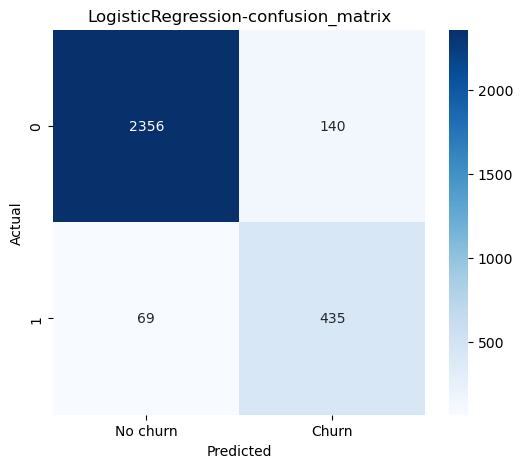

In [28]:
plt.figure(figsize=(6,5))
sns.heatmap(cm_Lr,annot=True,fmt='d',cmap='Blues',xticklabels=["No churn",'Churn'])
plt.title('LogisticRegression-confusion_matrix')
plt.xlabel("Predicted")
plt.ylabel('Actual')
plt.show()

In [29]:
from sklearn.ensemble import RandomForestClassifier

In [30]:
random_forest=Pipeline([
    ('preprocessor',preprocessor),('classifier',RandomForestClassifier(n_estimators=200,random_state=42,class_weight='balanced',n_jobs=-1))
])

In [31]:
random_forest.fit(X_train,y_train)
print("Rendom Forest Model trained Successfully!")

Rendom Forest Model trained Successfully!


In [32]:
y_pred_rf=random_forest.predict(X_test)
print("Predicition generated successfully!")
print(y_pred_rf[:20])

Predicition generated successfully!
[0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 1]


In [33]:
rf_accuracy=accuracy_score(y_test,y_pred_rf)
rf_precision=precision_score(y_test,y_pred_rf)
rf_recall=recall_score(y_test,y_pred_rf)
rf_f1=f1_score(y_test,y_pred_rf)

In [34]:
print("LogisticRegression Results")
print("Accuracy",round(rf_accuracy,4))
print("precision",round(rf_precision,4))
print("Recall:",round(rf_recall,4))
print("F1-score:",round(rf_f1,4))

LogisticRegression Results
Accuracy 0.9333
precision 0.7754
Recall: 0.8492
F1-score: 0.8106


In [35]:
print(classification_report(
    y_test,y_pred_rf,target_names=["No Churn","Churn"]
))

              precision    recall  f1-score   support

    No Churn       0.97      0.95      0.96      2496
       Churn       0.78      0.85      0.81       504

    accuracy                           0.93      3000
   macro avg       0.87      0.90      0.89      3000
weighted avg       0.94      0.93      0.93      3000



In [36]:
cm_rf=confusion_matrix(y_test,y_pred_Lr)
print(cm_rf)

[[2356  140]
 [  69  435]]


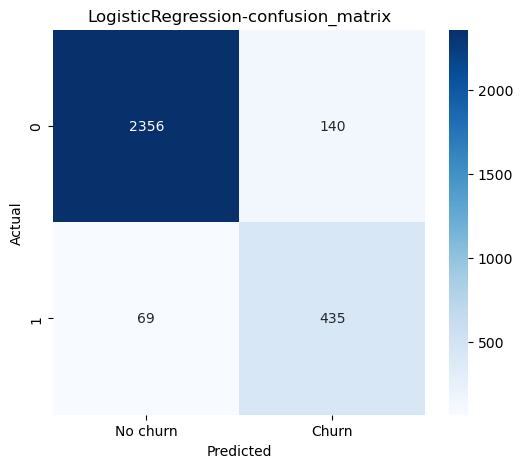

In [37]:
plt.figure(figsize=(6,5))
sns.heatmap(cm_rf,annot=True,fmt='d',cmap='Blues',xticklabels=["No churn",'Churn'])
plt.title('LogisticRegression-confusion_matrix')
plt.xlabel("Predicted")
plt.ylabel('Actual')
plt.show()

In [38]:
comparison=pd.DataFrame({
    "Model":['LogisticRegression'
    ,'random_forest'],
    "Accuracy":[Lr_accuracy,rf_accuracy],
    "precison":[Lr_precision,rf_precision],
    "Recall":[Lr_recall,rf_recall],
    "F1-Score":[Lr_f1,rf_f1]
})

In [39]:
comparison_rounded=comparison.copy()
numeric_columns=["Accuracy",'precison','Recall','F1-Score']

comparison_rounded[numeric_columns]=(comparison_rounded[numeric_columns].round(4))
comparison_rounded

,Model,Accuracy,precison,Recall,F1-Score
0,LogisticRegression,0.9303,0.7565,0.8631,0.8063
1,random_forest,0.9333,0.7754,0.8492,0.8106


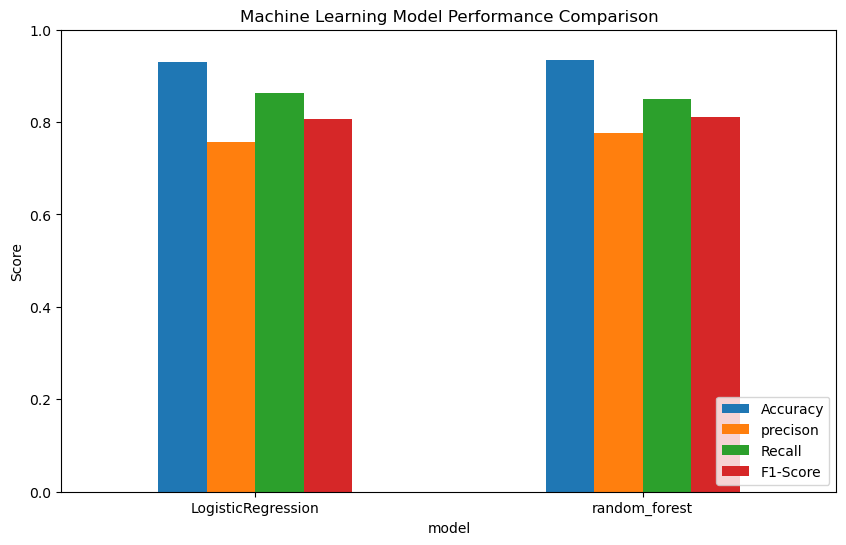

In [40]:
comparison_plot=comparison.set_index("Model")
comparison_plot.plot(kind='bar',figsize=(10,6))
plt.title("Machine Learning Model Performance Comparison")
plt.xlabel("model")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

In [41]:
best_model_name=comparison.loc[comparison['F1-Score'].idxmax(),'Model']
best_f1=comparison['F1-Score'].max()
print("Best Model:",best_model_name)
print("Best F1-Score:",round(best_f1,4))

Best Model: random_forest
Best F1-Score: 0.8106


In [42]:
Lr_probability=logistic_model.predict_proba(X_test)[:,1]
rf_probability=random_forest.predict_proba(X_test)[:,1]
Lr_auc=roc_auc_score(y_test,Lr_probability)
rf_auc=roc_auc_score(y_test,rf_probability)
print("Logistic Regression AUC:",round(Lr_auc,4))
print("Random Forest AUC:",round(rf_auc,4))

Logistic Regression AUC: 0.9454
Random Forest AUC: 0.9367


In [43]:
feature_names=(random_forest.named_steps['preprocessor'].get_feature_names_out())
importances=(random_forest.named_steps['classifier'].feature_importances_)
feature_importance=pd.DataFrame({'feature_names':feature_names,'importances':importances})
feature_importance_sorted=feature_importance.sort_values(by='importances',ascending=False)  
feature_importance.head(15)

,feature_names,importances
0,num__age,0.058029
1,num__tenure_months,0.049088
2,num__monthly_charges,0.049524
3,num__total_charges,0.048749
4,num__support_calls,0.025401
5,num__complaints,0.019191
6,num__late_payments,0.020113
7,num__satisfaction_score,0.079330
8,num__is_active,0.503940
9,cat__gender_Female,0.007013


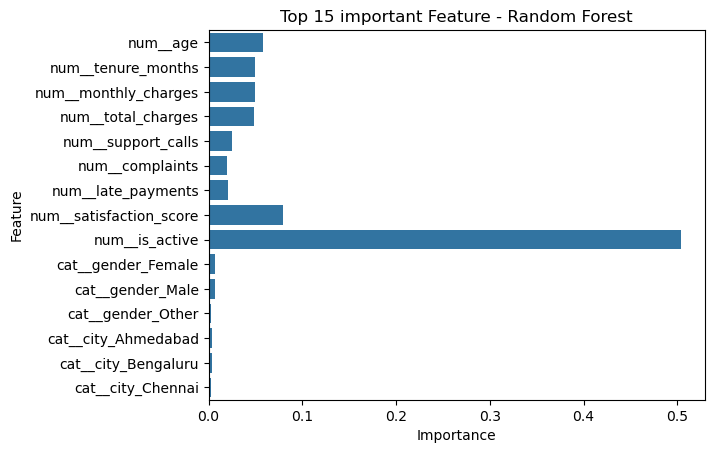

In [44]:
top_features=feature_importance.head(15)
plt.Figure(figsize=(10,7))
sns.barplot(data=top_features,x='importances',y='feature_names')
plt.title('Top 15 important Feature - Random Forest')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

In [45]:
import joblib

In [46]:
if best_model_name=="LogisticRegression":
    best_model=logistic_model
else:
    best_model=random_forest
joblib.dump(best_model,"customer_churn_best_model.pkl")

print('Best model saved successfully!')

Best model saved successfully!


In [47]:
joblib.dump(logistic_model,"customer_churn_logistic_regression.pkl")
joblib.dump(random_forest,"customer_churn_random_forest.pkl ")
print("Both models saved successfully!")

Both models saved successfully!


In [48]:
comparison_rounded.to_csv("model_comparison.csv",index=False)
print("Model comparison saved successfully!")

Model comparison saved successfully!


In [49]:
loaded_model=joblib.load("customer_churn_best_model.pkl")
test_predictions=loaded_model.predict(X_test)
print("Loaded model prediction sucessful!")
print(test_predictions[:20])

Loaded model prediction sucessful!
[0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 1]
